In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Simmi_PHD/Training_data"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

In [ ]:
# VGG 16

In [13]:
import os
import torch
import torch.nn as nn
from torchvision import datasets
from torchvision.models import vgg16, VGG16_Weights
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import pickle

In [14]:
import os
import torch
import torch.nn as nn
from torchvision import datasets
from torchvision.models import vgg16, VGG16_Weights
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import pickle

# ------------------------
# Paths & Setup
# ------------------------
data_dir = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"
checkpoint_dir = "/content/drive/MyDrive/Classification/Weights/VGGNet_ashu"
os.makedirs(checkpoint_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# Model & Transform
# ------------------------
weights = VGG16_Weights.DEFAULT
transform = weights.transforms()

# ------------------------
# Binary VGG16 Model
# ------------------------
class VGG16Binary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = VGG16_Weights.DEFAULT
        self.model = vgg16(weights=weights)
        in_features = self.model.classifier[-1].in_features
        self.model.classifier[-1] = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Instantiate model
model = VGG16Binary().to(device)

# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)

# Split 80/20
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50

best_val_loss = float('inf')

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print(f"Device: {device}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Total epochs: {num_epochs}")
print(f"Checkpoint directory: {checkpoint_dir}")

Device: cuda
Number of training samples: 2364
Number of validation samples: 591
Total epochs: 50
Checkpoint directory: /content/drive/MyDrive/Classification/Weights/VGGNet_ashu


In [ ]:
# ------------------------
# Training Loop
# ------------------------

for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ============================================================
    # TRAINING
    # ============================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * labels.size(0)

        # Predictions
        preds = (outputs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    # Epoch training metrics
    train_loss = running_loss / total
    train_acc = correct / total


    # ============================================================
    # VALIDATION
    # ============================================================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            # Predictions
            preds = (outputs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    # Epoch validation metrics
    val_loss /= val_total
    val_acc = val_correct / val_total


    # ============================================================
    # STORE HISTORY
    # ============================================================
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    # ============================================================
    # SAVE WEIGHTS AFTER EVERY EPOCH
    # ============================================================

    epoch_checkpoint_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_weights.pth"
    )

    torch.save(
        model.state_dict(),
        epoch_checkpoint_path
    )


    # ============================================================
    # SAVE COMPLETE CHECKPOINT
    # ============================================================
    # This is useful if you want to RESUME training later.

    epoch_checkpoint_full_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        },
        epoch_checkpoint_full_path
    )


    # ============================================================
    # SAVE BEST MODEL
    # ============================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_weights.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"\n✅ New best model saved "
            f"(Epoch {epoch}, Val Loss = {val_loss:.4f})"
        )


    # ============================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ============================================================

    history_path = os.path.join(
        checkpoint_dir,
        "training_history.pkl"
    )

    with open(history_path, "wb") as f:
        pickle.dump(history, f)


    # ============================================================
    # PRINT EPOCH RESULTS
    # ============================================================

    print(
        f"Epoch {epoch:2d}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"All epoch weights saved in:")
print(checkpoint_dir)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]


✅ New best model saved (Epoch 1, Val Loss = 0.2831)


Epochs:   2%|▏         | 1/50 [19:45<16:08:10, 1185.52s/it]

Epoch  1: Train Loss: 0.4638, Train Acc: 0.7741, Val Loss: 0.2831, Val Acc: 0.8832


Epochs:   4%|▍         | 2/50 [21:07<7:09:14, 536.54s/it]  

...

Epoch 48: Train Loss: 0.0000, Train Acc: 1.0000, Val Loss: 0.4609, Val Acc: 0.9594


Epochs:  98%|█████████▊| 49/50 [1:38:44<01:29, 89.71s/it]

Epoch 49: Train Loss: 0.0000, Train Acc: 1.0000, Val Loss: 0.4633, Val Acc: 0.9594


Epochs: 100%|██████████| 50/50 [1:40:10<00:00, 120.20s/it]

Epoch 50: Train Loss: 0.0000, Train Acc: 1.0000, Val Loss: 0.4653, Val Acc: 0.9594

TRAINING COMPLETED
Best Validation Loss: 0.1508
All epoch weights saved in:
/content/drive/MyDrive/Classification/Weights/VGGNet_ashu


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights
from torchvision.io import read_image
from torchvision.transforms import functional as TF
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------
# Device and Model
# ----------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights = DenseNet121_Weights.DEFAULT
transform = weights.transforms()



class DenseNetBinary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.model = densenet121(weights=weights)
        in_features = self.model.classifier.in_features
        self.model.classifier = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)



model = VGG16Binary().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Classification/Weights/VGGNet_ashu/epoch_14_weights.pth"))  # ← replace with your path
model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            path = os.path.join(folder, fname)
            image = read_image(path).float() / 255.0
            image = transform(image).unsqueeze(0).to(device)

            output = model(image)
            pred = 1 if output.item() > 0.5 else 0

            # Accuracy for deviation
            correct = (pred == label)
            accuracies.append(int(correct))

            # Confusion matrix components
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            elif pred == 0 and label == 1:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

# ----------------------
# Save CSV
# ----------------------
results = {
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
df.to_csv("/content/drive/MyDrive/Classification/Results/VGGNet/Vgg16_top_results_epoch14.csv", index=False)
print("\n✅ Results saved to 'Vgg16_top_results.csv'")


Evaluating b_cancer: 100%|██████████| 164/164 [00:04<00:00, 40.16it/s]



✅ Results saved to 'Vgg16_top_results.csv'


Using device: cuda

Model loaded successfully.
Weights path:
/content/drive/MyDrive/Classification/Weights/VGGNet_ashu/epoch_14_weights.pth


Evaluating b_cancer: 100%|██████████| 164/164 [00:02<00:00, 67.33it/s]



Calculating 95% confidence intervals...


VGG16 MODEL TEST RESULTS
Total Images Tested: 328

Confusion Matrix Components:
TP: 146
FP: 10
TN: 154
FN: 18

Performance Metrics:
Accuracy:     0.9146 (91.46%)
Sensitivity:  0.8902 (89.02%)
Specificity:  0.9390 (93.90%)
Precision:    0.9359 (93.59%)
F1-Score:     0.9125
Accuracy StdDev: 0.2794

95% Confidence Intervals:
Accuracy CI: [0.8811, 0.9451]
Sensitivity CI: [0.8366, 0.9368]
Specificity CI: [0.9007, 0.9727]
Precision CI: [0.8951, 0.9724]
F1-Score CI: [0.8774, 0.9426]

Calibration Metrics:
Brier Score: 0.084211
Expected Calibration Error (ECE): 0.087212
Maximum Calibration Error (MCE): 0.436823
ROC-AUC: 0.932276
Average Precision: 0.929911

Summary results saved to:
/content/drive/MyDrive/Classification/Results/VGGNet/Calibration_analysis/VGG16_epoch_14_all_metrics.csv
Detailed predictions saved to:
/content/drive/MyDrive/Classification/Results/VGGNet/Calibration_analysis/VGG16_epoch_14_detailed_predictions.csv
Calibration bin data sav

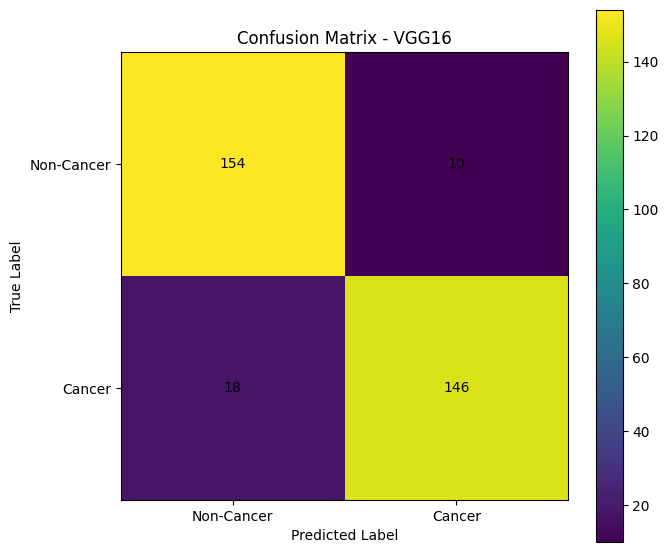

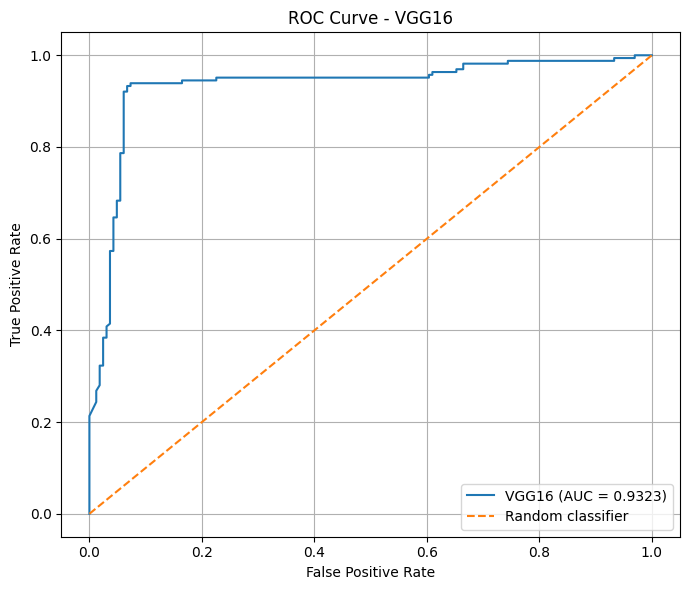

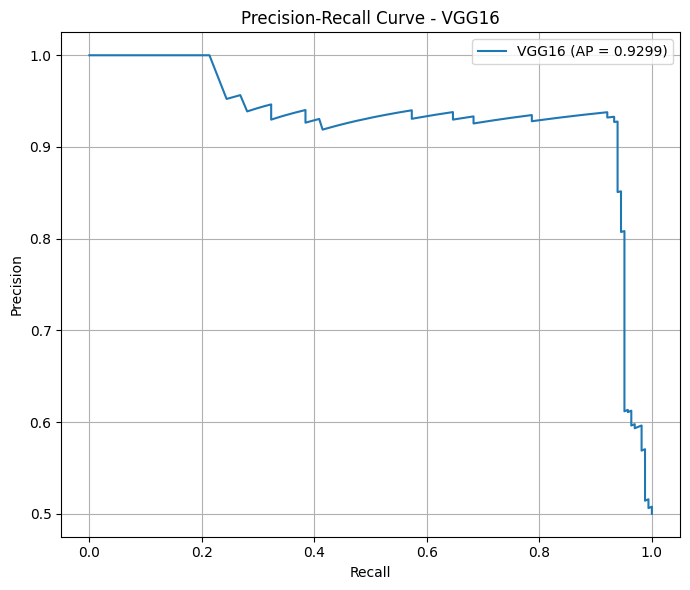

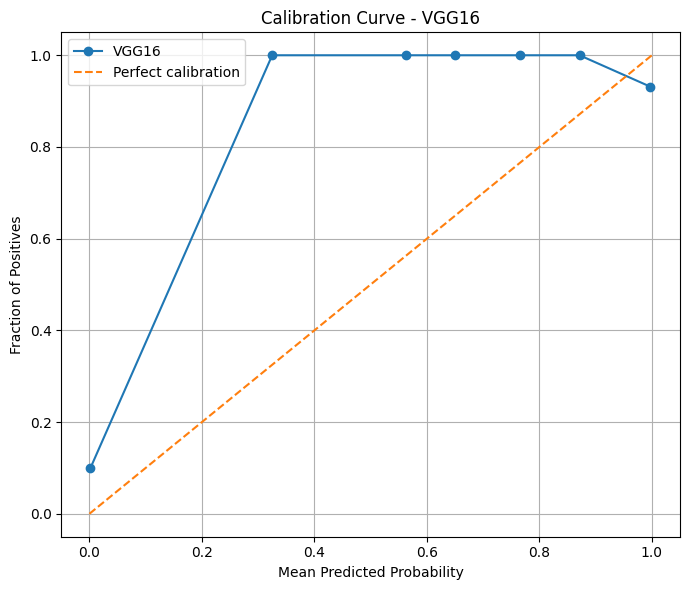

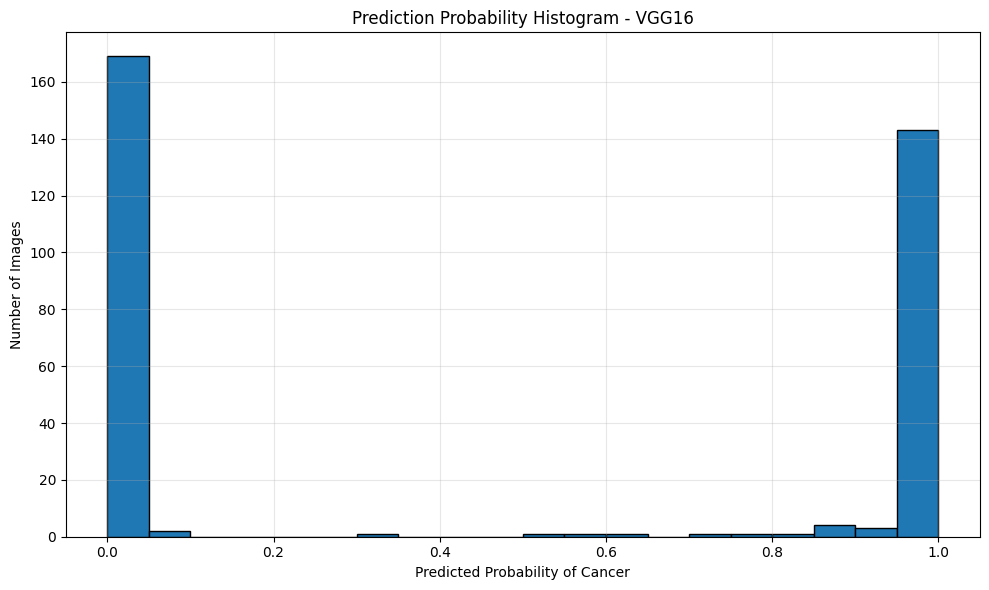

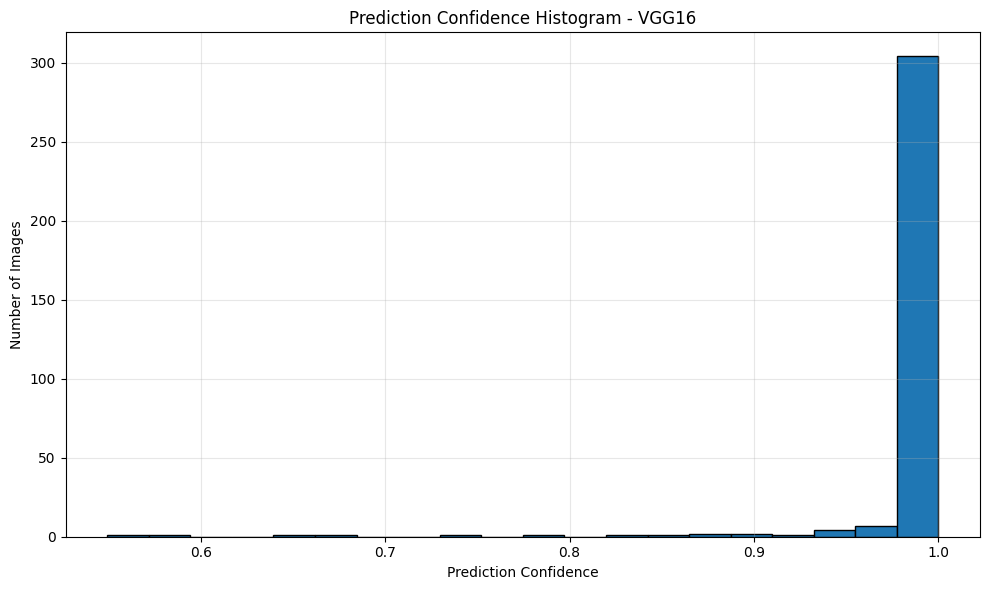

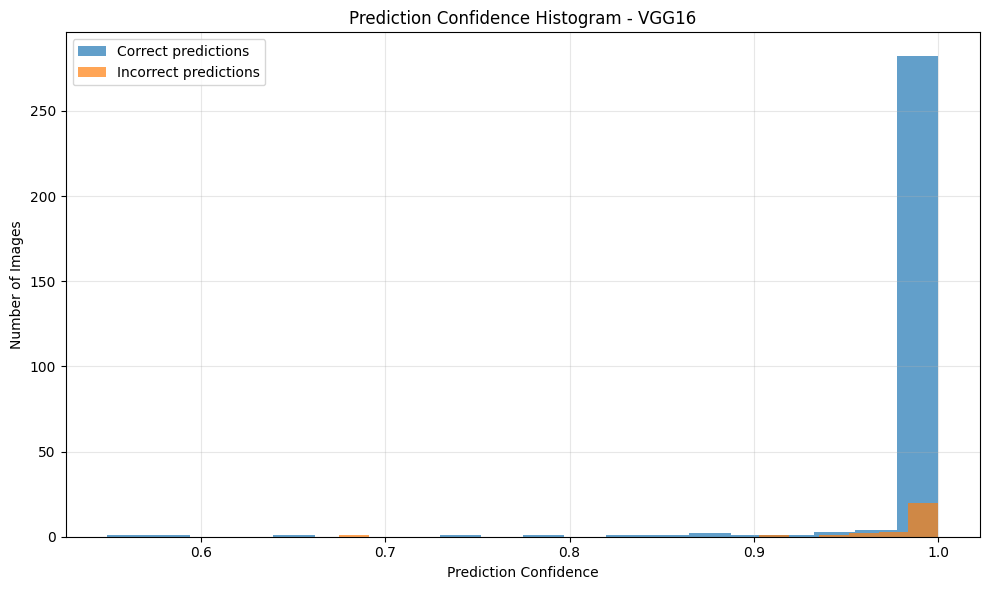

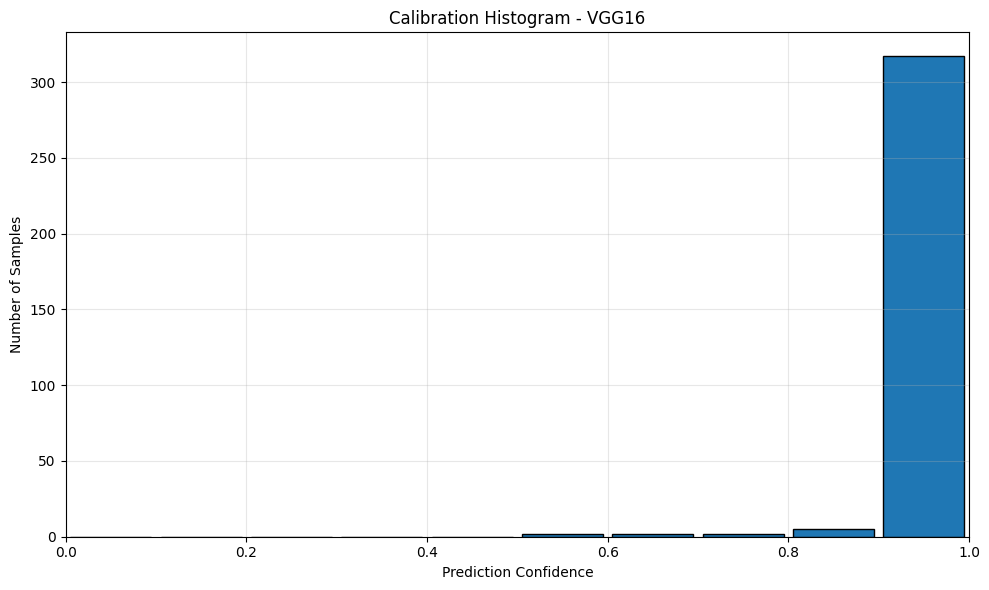

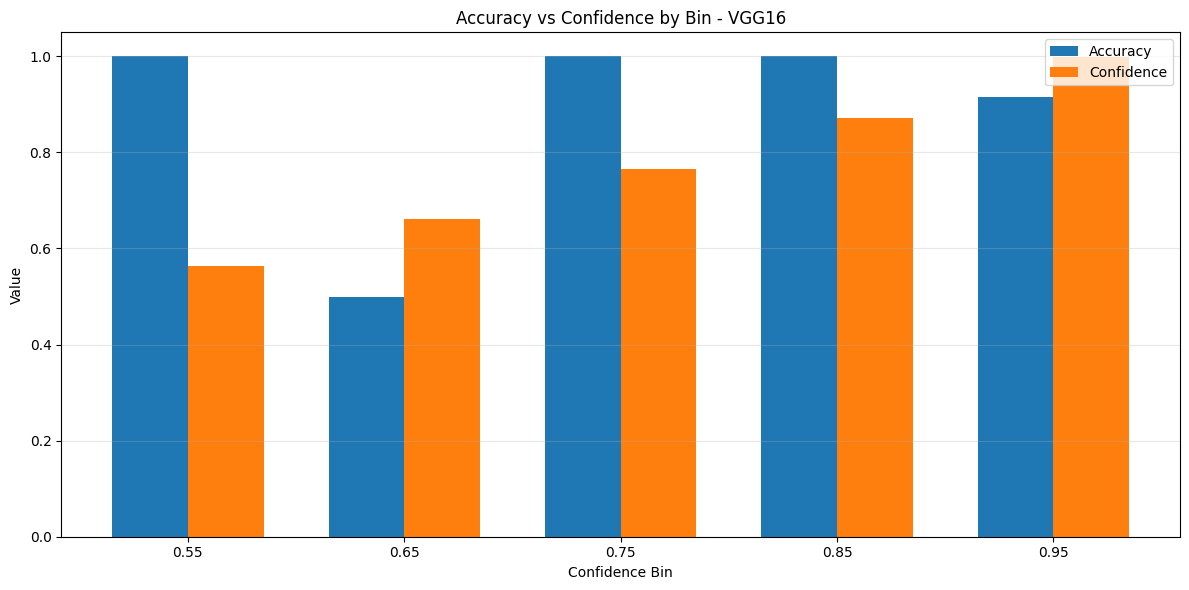


ALL EVALUATION COMPLETE

Saved files:
1. VGG16_epoch_14_all_metrics.csv
2. VGG16_epoch_14_detailed_predictions.csv
3. VGG16_epoch_14_calibration_bins.csv
4. VGG16_confusion_matrix.png
5. VGG16_ROC_curve.png
6. VGG16_precision_recall_curve.png
7. VGG16_calibration_curve.png
8. VGG16_probability_histogram.png
9. VGG16_confidence_histogram.png
10. VGG16_correct_incorrect_confidence_histogram.png
11. VGG16_calibration_histogram.png
12. VGG16_accuracy_vs_confidence.png

All results saved in:
/content/drive/MyDrive/Classification/Results/VGGNet/Calibration_analysis


In [16]:
# ============================================================
# COMPLETE VGG16 TEST EVALUATION + CALIBRATION + ALL PLOTS
# ============================================================

import os
import random
import warnings

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from torchvision.models import vgg16, VGG16_Weights
from torchvision.io import read_image

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from sklearn.calibration import calibration_curve
from scipy.stats import binomtest

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ============================================================
# 3. PATHS
# ============================================================

weights_path = (
    "/content/drive/MyDrive/Classification/"
    "Weights/VGGNet_ashu/"
    "epoch_14_weights.pth"
)

test_root = (
    "/content/drive/MyDrive/Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2"
)

save_dir = (
    "/content/drive/MyDrive/Classification/"
    "Results/VGGNet/Calibration_analysis"
)

os.makedirs(save_dir, exist_ok=True)


# ============================================================
# 4. VGG16 BINARY MODEL
# ============================================================

class VGG16Binary(nn.Module):

    def __init__(self):
        super().__init__()

        weights = VGG16_Weights.DEFAULT

        self.model = vgg16(weights=weights)

        in_features = self.model.classifier[6].in_features

        self.model.classifier[6] = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


# ============================================================
# 5. LOAD MODEL
# ============================================================

model = VGG16Binary().to(device)

checkpoint = torch.load(
    weights_path,
    map_location=device
)

# Handle checkpoints that may contain state_dict
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

# Remove "module." prefix if DataParallel was used
clean_checkpoint = {}

for key, value in checkpoint.items():

    if key.startswith("module."):
        key = key.replace("module.", "", 1)

    clean_checkpoint[key] = value


model.load_state_dict(
    clean_checkpoint,
    strict=True
)

model.eval()

print("\nModel loaded successfully.")
print("Weights path:")
print(weights_path)


# ============================================================
# 6. TRANSFORM
# ============================================================

weights = VGG16_Weights.DEFAULT
transform = weights.transforms()


# ============================================================
# 7. TEST DATA
# ============================================================

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}


# ============================================================
# 8. ECE AND MCE FUNCTION
# ============================================================

def calculate_ece_mce(
    probabilities,
    labels,
    n_bins=10
):

    probabilities = np.asarray(probabilities)
    labels = np.asarray(labels)

    # Confidence of predicted class
    confidences = np.maximum(
        probabilities,
        1.0 - probabilities
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    correctness = (
        predictions == labels
    ).astype(float)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0
    mce = 0.0

    bin_accuracy = []
    bin_confidence = []
    bin_counts = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (confidences >= lower) &
                (confidences <= upper)
            )

        else:

            mask = (
                (confidences >= lower) &
                (confidences < upper)
            )

        count = np.sum(mask)

        if count > 0:

            accuracy_bin = np.mean(
                correctness[mask]
            )

            confidence_bin = np.mean(
                confidences[mask]
            )

            calibration_gap = abs(
                accuracy_bin - confidence_bin
            )

            ece += (
                count / len(confidences)
            ) * calibration_gap

            mce = max(
                mce,
                calibration_gap
            )

            bin_accuracy.append(
                accuracy_bin
            )

            bin_confidence.append(
                confidence_bin
            )

            bin_counts.append(
                count
            )

        else:

            bin_accuracy.append(np.nan)
            bin_confidence.append(np.nan)
            bin_counts.append(0)

    return (
        ece,
        mce,
        bin_edges,
        bin_accuracy,
        bin_confidence,
        bin_counts
    )


# ============================================================
# 9. BRIER SCORE FUNCTION
# ============================================================

def calculate_brier_score(
    probabilities,
    labels
):

    probabilities = np.asarray(probabilities)
    labels = np.asarray(labels)

    return np.mean(
        (probabilities - labels) ** 2
    )


# ============================================================
# 10. BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

def bootstrap_metric_ci(
    labels,
    predictions,
    metric_function,
    n_bootstrap=2000,
    confidence_level=0.95,
    seed=42
):

    labels = np.asarray(labels)
    predictions = np.asarray(predictions)

    rng = np.random.default_rng(seed)

    n_samples = len(labels)

    bootstrap_values = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            n_samples,
            size=n_samples
        )

        y_true_boot = labels[indices]
        y_pred_boot = predictions[indices]

        value = metric_function(
            y_true_boot,
            y_pred_boot
        )

        bootstrap_values.append(value)

    alpha = 1 - confidence_level

    lower = np.percentile(
        bootstrap_values,
        100 * (alpha / 2)
    )

    upper = np.percentile(
        bootstrap_values,
        100 * (1 - alpha / 2)
    )

    return lower, upper


# ============================================================
# 11. METRIC FUNCTIONS FOR BOOTSTRAP CI
# ============================================================

def metric_accuracy(y_true, y_pred):

    TP = np.sum(
        (y_pred == 1) &
        (y_true == 1)
    )

    TN = np.sum(
        (y_pred == 0) &
        (y_true == 0)
    )

    total = len(y_true)

    return (
        (TP + TN) / total
        if total else 0
    )


def metric_sensitivity(y_true, y_pred):

    TP = np.sum(
        (y_pred == 1) &
        (y_true == 1)
    )

    FN = np.sum(
        (y_pred == 0) &
        (y_true == 1)
    )

    return (
        TP / (TP + FN)
        if (TP + FN) else 0
    )


def metric_specificity(y_true, y_pred):

    TN = np.sum(
        (y_pred == 0) &
        (y_true == 0)
    )

    FP = np.sum(
        (y_pred == 1) &
        (y_true == 0)
    )

    return (
        TN / (TN + FP)
        if (TN + FP) else 0
    )


def metric_precision(y_true, y_pred):

    TP = np.sum(
        (y_pred == 1) &
        (y_true == 1)
    )

    FP = np.sum(
        (y_pred == 1) &
        (y_true == 0)
    )

    return (
        TP / (TP + FP)
        if (TP + FP) else 0
    )


def metric_f1(y_true, y_pred):

    sensitivity = metric_sensitivity(
        y_true,
        y_pred
    )

    precision = metric_precision(
        y_true,
        y_pred
    )

    return (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (precision + sensitivity) else 0
    )


# ============================================================
# 12. EVALUATION LOOP
# ============================================================

TP = FP = TN = FN = 0

accuracies = []

all_probabilities = []
all_predictions = []
all_labels = []
all_correct = []

all_filenames = []
all_classes = []


with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"\nWarning: Folder does not exist: {folder}"
            )

            continue

        filenames = sorted(
            os.listdir(folder)
        )

        for fname in tqdm(
            filenames,
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):
                continue

            path = os.path.join(
                folder,
                fname
            )

            try:

                # ------------------------------------
                # Read image
                # ------------------------------------

                image = (
                    read_image(path)
                    .float()
                    / 255.0
                )

                # ------------------------------------
                # Apply VGG16 transform
                # ------------------------------------

                image = transform(
                    image
                ).unsqueeze(0).to(device)

                # ------------------------------------
                # Model prediction
                # ------------------------------------

                output = model(image)

                probability = float(
                    output.squeeze().item()
                )

                pred = (
                    1
                    if probability > 0.5
                    else 0
                )

                correct = int(
                    pred == label
                )

                # ------------------------------------
                # Store results
                # ------------------------------------

                all_probabilities.append(
                    probability
                )

                all_predictions.append(
                    pred
                )

                all_labels.append(
                    label
                )

                all_correct.append(
                    correct
                )

                all_filenames.append(
                    fname
                )

                all_classes.append(
                    cls_name
                )

                accuracies.append(
                    correct
                )

                # ------------------------------------
                # Confusion matrix components
                # ------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1


            except Exception as e:

                print(
                    f"\nError processing "
                    f"{fname}: {e}"
                )


# ============================================================
# 13. CONVERT TO NUMPY ARRAYS
# ============================================================

all_probabilities = np.array(
    all_probabilities
)

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

all_correct = np.array(
    all_correct
)


# ============================================================
# 14. PERFORMANCE METRICS
# ============================================================

# Use the exact formulas requested

total = TP + FP + TN + FN

accuracy = (
    (TP + TN) / total
    if total else 0
)

sensitivity = (
    TP / (TP + FN)
    if (TP + FN) else 0
)

specificity = (
    TN / (TN + FP)
    if (TN + FP) else 0
)

precision = (
    TP / (TP + FP)
    if (TP + FP) else 0
)

f1_score = (
    2 * (precision * sensitivity) /
    (precision + sensitivity)
    if (precision + sensitivity) else 0
)

deviation = (
    np.std(accuracies)
    if len(accuracies) > 0
    else 0
)


# ============================================================
# 15. CALIBRATION METRICS
# ============================================================

brier_score = calculate_brier_score(
    all_probabilities,
    all_labels
)

(
    ece,
    mce,
    bin_edges,
    bin_accuracy,
    bin_confidence,
    bin_counts
) = calculate_ece_mce(
    all_probabilities,
    all_labels,
    n_bins=10
)


# ============================================================
# 16. ROC AUC
# ============================================================

try:

    roc_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    fpr, tpr, roc_thresholds = roc_curve(
        all_labels,
        all_probabilities
    )

except Exception as e:

    print("ROC calculation error:", e)

    roc_auc = np.nan
    fpr = None
    tpr = None


# ============================================================
# 17. PRECISION-RECALL CURVE
# ============================================================

try:

    precision_curve, recall_curve, pr_thresholds = (
        precision_recall_curve(
            all_labels,
            all_probabilities
        )
    )

    average_precision = average_precision_score(
        all_labels,
        all_probabilities
    )

except Exception as e:

    print("PR calculation error:", e)

    precision_curve = None
    recall_curve = None
    average_precision = np.nan


# ============================================================
# 18. CALIBRATION CURVE
# ============================================================

try:

    fraction_of_positives, mean_predicted_value = (
        calibration_curve(
            all_labels,
            all_probabilities,
            n_bins=10,
            strategy="uniform"
        )
    )

except Exception as e:

    print("Calibration curve error:", e)

    fraction_of_positives = None
    mean_predicted_value = None


# ============================================================
# 19. 95% BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

print(
    "\nCalculating 95% confidence intervals..."
)

accuracy_ci_low, accuracy_ci_high = (
    bootstrap_metric_ci(
        all_labels,
        all_predictions,
        metric_accuracy,
        n_bootstrap=2000
    )
)

sensitivity_ci_low, sensitivity_ci_high = (
    bootstrap_metric_ci(
        all_labels,
        all_predictions,
        metric_sensitivity,
        n_bootstrap=2000
    )
)

specificity_ci_low, specificity_ci_high = (
    bootstrap_metric_ci(
        all_labels,
        all_predictions,
        metric_specificity,
        n_bootstrap=2000
    )
)

precision_ci_low, precision_ci_high = (
    bootstrap_metric_ci(
        all_labels,
        all_predictions,
        metric_precision,
        n_bootstrap=2000
    )
)

f1_ci_low, f1_ci_high = (
    bootstrap_metric_ci(
        all_labels,
        all_predictions,
        metric_f1,
        n_bootstrap=2000
    )
)


# ============================================================
# 20. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("VGG16 MODEL TEST RESULTS")
print("=" * 70)

print(f"Total Images Tested: {total}")

print("\nConfusion Matrix Components:")

print(f"TP: {TP}")
print(f"FP: {FP}")
print(f"TN: {TN}")
print(f"FN: {FN}")

print("\nPerformance Metrics:")

print(
    f"Accuracy:     {accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Sensitivity:  {sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"Specificity:  {specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"Precision:    {precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"F1-Score:     {f1_score:.4f}"
)

print(
    f"Accuracy StdDev: {deviation:.4f}"
)


print("\n95% Confidence Intervals:")

print(
    f"Accuracy CI: "
    f"[{accuracy_ci_low:.4f}, "
    f"{accuracy_ci_high:.4f}]"
)

print(
    f"Sensitivity CI: "
    f"[{sensitivity_ci_low:.4f}, "
    f"{sensitivity_ci_high:.4f}]"
)

print(
    f"Specificity CI: "
    f"[{specificity_ci_low:.4f}, "
    f"{specificity_ci_high:.4f}]"
)

print(
    f"Precision CI: "
    f"[{precision_ci_low:.4f}, "
    f"{precision_ci_high:.4f}]"
)

print(
    f"F1-Score CI: "
    f"[{f1_ci_low:.4f}, "
    f"{f1_ci_high:.4f}]"
)


print("\nCalibration Metrics:")

print(
    f"Brier Score: {brier_score:.6f}"
)

print(
    f"Expected Calibration Error (ECE): "
    f"{ece:.6f}"
)

print(
    f"Maximum Calibration Error (MCE): "
    f"{mce:.6f}"
)

print(
    f"ROC-AUC: {roc_auc:.6f}"
)

print(
    f"Average Precision: "
    f"{average_precision:.6f}"
)

print("=" * 70)


# ============================================================
# 21. SAVE SUMMARY CSV
# ============================================================

results = {
    "Model": [
        "VGG16"
    ],

    "TP": [TP],
    "FP": [FP],
    "TN": [TN],
    "FN": [FN],

    "Total": [total],

    "Accuracy": [
        round(accuracy, 4)
    ],

    "Accuracy CI Lower": [
        round(accuracy_ci_low, 4)
    ],

    "Accuracy CI Upper": [
        round(accuracy_ci_high, 4)
    ],

    "Sensitivity": [
        round(sensitivity, 4)
    ],

    "Sensitivity CI Lower": [
        round(sensitivity_ci_low, 4)
    ],

    "Sensitivity CI Upper": [
        round(sensitivity_ci_high, 4)
    ],

    "Specificity": [
        round(specificity, 4)
    ],

    "Specificity CI Lower": [
        round(specificity_ci_low, 4)
    ],

    "Specificity CI Upper": [
        round(specificity_ci_high, 4)
    ],

    "Precision": [
        round(precision, 4)
    ],

    "Precision CI Lower": [
        round(precision_ci_low, 4)
    ],

    "Precision CI Upper": [
        round(precision_ci_high, 4)
    ],

    "F1-Score": [
        round(f1_score, 4)
    ],

    "F1-Score CI Lower": [
        round(f1_ci_low, 4)
    ],

    "F1-Score CI Upper": [
        round(f1_ci_high, 4)
    ],

    "Accuracy StdDev": [
        round(deviation, 4)
    ],

    "Brier Score": [
        round(brier_score, 6)
    ],

    "ECE": [
        round(ece, 6)
    ],

    "MCE": [
        round(mce, 6)
    ],

    "ROC-AUC": [
        round(roc_auc, 6)
    ],

    "Average Precision": [
        round(average_precision, 6)
    ]
}

results_df = pd.DataFrame(
    results
)

summary_csv = os.path.join(
    save_dir,
    "VGG16_epoch_14_all_metrics.csv"
)

results_df.to_csv(
    summary_csv,
    index=False
)

print(
    f"\nSummary results saved to:\n"
    f"{summary_csv}"
)


# ============================================================
# 22. SAVE DETAILED PREDICTIONS
# ============================================================

prediction_confidence = np.maximum(
    all_probabilities,
    1 - all_probabilities
)

detailed_results = pd.DataFrame({

    "Filename": all_filenames,

    "Class": all_classes,

    "True_Label": all_labels,

    "Probability_Cancer": all_probabilities,

    "Prediction": all_predictions,

    "Confidence": prediction_confidence,

    "Correct": all_correct

})

detailed_csv = os.path.join(
    save_dir,
    "VGG16_epoch_14_detailed_predictions.csv"
)

detailed_results.to_csv(
    detailed_csv,
    index=False
)

print(
    f"Detailed predictions saved to:\n"
    f"{detailed_csv}"
)


# ============================================================
# 23. SAVE CALIBRATION BIN DATA
# ============================================================

calibration_bin_df = pd.DataFrame({

    "Bin Lower": bin_edges[:-1],

    "Bin Upper": bin_edges[1:],

    "Number of Samples": bin_counts,

    "Mean Confidence": bin_confidence,

    "Accuracy": bin_accuracy

})

calibration_bin_csv = os.path.join(
    save_dir,
    "VGG16_epoch_14_calibration_bins.csv"
)

calibration_bin_df.to_csv(
    calibration_bin_csv,
    index=False
)

print(
    f"Calibration bin data saved to:\n"
    f"{calibration_bin_csv}"
)


# ============================================================
# 24. CONFUSION MATRIX PLOT
# ============================================================

cm = np.array([
    [TN, FP],
    [FN, TP]
])

fig, ax = plt.subplots(
    figsize=(7, 6)
)

im = ax.imshow(cm)

ax.set_title(
    "Confusion Matrix - VGG16"
)

ax.set_xlabel(
    "Predicted Label"
)

ax.set_ylabel(
    "True Label"
)

ax.set_xticks([0, 1])

ax.set_xticklabels([
    "Non-Cancer",
    "Cancer"
])

ax.set_yticks([0, 1])

ax.set_yticklabels([
    "Non-Cancer",
    "Cancer"
])

for i in range(2):

    for j in range(2):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

fig.colorbar(im)

plt.tight_layout()

plt.savefig(
    os.path.join(
        save_dir,
        "VGG16_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 25. ROC CURVE
# ============================================================

if fpr is not None:

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            f"VGG16 "
            f"(AUC = {roc_auc:.4f})"
        )
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random classifier"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        "ROC Curve - VGG16"
    )

    plt.legend(
        loc="lower right"
    )

    plt.grid()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            save_dir,
            "VGG16_ROC_curve.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 26. PRECISION-RECALL CURVE
# ============================================================

if precision_curve is not None:

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        recall_curve,
        precision_curve,
        label=(
            f"VGG16 "
            f"(AP = {average_precision:.4f})"
        )
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        "Precision-Recall Curve - VGG16"
    )

    plt.legend()

    plt.grid()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            save_dir,
            "VGG16_precision_recall_curve.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 27. CALIBRATION / RELIABILITY CURVE
# ============================================================

if mean_predicted_value is not None:

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        mean_predicted_value,
        fraction_of_positives,
        marker="o",
        label="VGG16"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    plt.xlabel(
        "Mean Predicted Probability"
    )

    plt.ylabel(
        "Fraction of Positives"
    )

    plt.title(
        "Calibration Curve - VGG16"
    )

    plt.legend()

    plt.grid()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            save_dir,
            "VGG16_calibration_curve.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 28. PREDICTED PROBABILITY HISTOGRAM
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    all_probabilities,
    bins=20,
    edgecolor="black"
)

plt.xlabel(
    "Predicted Probability of Cancer"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Prediction Probability Histogram - VGG16"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        save_dir,
        "VGG16_probability_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 29. CONFIDENCE HISTOGRAM
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    prediction_confidence,
    bins=20,
    edgecolor="black"
)

plt.xlabel(
    "Prediction Confidence"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Prediction Confidence Histogram - VGG16"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        save_dir,
        "VGG16_confidence_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 30. CORRECT vs INCORRECT CONFIDENCE HISTOGRAM
#     SAME TYPE OF PLOT AS THE ONE YOU PROVIDED
# ============================================================

correct_confidences = prediction_confidence[
    all_correct == 1
]

incorrect_confidences = prediction_confidence[
    all_correct == 0
]

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    correct_confidences,
    bins=20,
    alpha=0.7,
    label="Correct predictions"
)

plt.hist(
    incorrect_confidences,
    bins=20,
    alpha=0.7,
    label="Incorrect predictions"
)

plt.xlabel(
    "Prediction Confidence"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Prediction Confidence Histogram - VGG16"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        save_dir,
        "VGG16_correct_incorrect_confidence_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 31. CALIBRATION HISTOGRAM
# ============================================================

bin_centers = (
    bin_edges[:-1] +
    bin_edges[1:]
) / 2

bin_width = (
    bin_edges[1] -
    bin_edges[0]
)

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    bin_centers,
    bin_counts,
    width=bin_width * 0.9,
    edgecolor="black"
)

plt.xlabel(
    "Prediction Confidence"
)

plt.ylabel(
    "Number of Samples"
)

plt.title(
    "Calibration Histogram - VGG16"
)

plt.xlim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        save_dir,
        "VGG16_calibration_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 32. CONFIDENCE vs ACCURACY CALIBRATION BAR PLOT
# ============================================================

valid_indices = [
    i
    for i in range(len(bin_counts))
    if bin_counts[i] > 0
]

valid_centers = [
    bin_centers[i]
    for i in valid_indices
]

valid_accuracy = [
    bin_accuracy[i]
    for i in valid_indices
]

valid_confidence = [
    bin_confidence[i]
    for i in valid_indices
]


x = np.arange(
    len(valid_indices)
)

width = 0.35

plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width / 2,
    valid_accuracy,
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    valid_confidence,
    width,
    label="Confidence"
)

plt.xlabel(
    "Confidence Bin"
)

plt.ylabel(
    "Value"
)

plt.title(
    "Accuracy vs Confidence by Bin - VGG16"
)

plt.xticks(
    x,
    [
        f"{valid_centers[i]:.2f}"
        for i in range(len(valid_centers))
    ]
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        save_dir,
        "VGG16_accuracy_vs_confidence.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 33. OPTIONAL McNEMAR'S TEST
# ============================================================
#
# To compare VGG16 with another model, both models must be
# evaluated on EXACTLY the same test images.
#
# Set this to the detailed predictions CSV of another model.
#
# Example:
#
# comparison_csv =
#     "/content/drive/MyDrive/Classification/"
#     "Results/Swin_Transformers/"
#     "swin_detailed_predictions.csv"
#
# Leave as None if you do not want comparison.
# ============================================================

comparison_csv = None


def mcnemar_exact_test(
    model1_correct,
    model2_correct
):

    model1_correct = np.asarray(
        model1_correct
    )

    model2_correct = np.asarray(
        model2_correct
    )

    # Model 1 correct, Model 2 incorrect
    b = np.sum(
        (model1_correct == 1) &
        (model2_correct == 0)
    )

    # Model 1 incorrect, Model 2 correct
    c = np.sum(
        (model1_correct == 0) &
        (model2_correct == 1)
    )

    n_discordant = b + c

    if n_discordant == 0:

        return b, c, 1.0

    p_value = binomtest(
        min(b, c),
        n=n_discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue

    return b, c, p_value


if comparison_csv is not None and os.path.exists(comparison_csv):

    comparison_df = pd.read_csv(
        comparison_csv
    )

    # Sort by filename to ensure corresponding images are aligned
    vgg_df = detailed_results.sort_values(
        "Filename"
    ).reset_index(drop=True)

    comparison_df = comparison_df.sort_values(
        "Filename"
    ).reset_index(drop=True)

    if len(vgg_df) != len(comparison_df):

        print(
            "\nMcNemar test skipped: "
            "different number of test samples."
        )

    elif not np.array_equal(
        vgg_df["Filename"].values,
        comparison_df["Filename"].values
    ):

        print(
            "\nMcNemar test skipped: "
            "test images are not aligned."
        )

    else:

        b, c, p_value = mcnemar_exact_test(
            vgg_df["Correct"].values,
            comparison_df["Correct"].values
        )

        print("\n" + "=" * 70)
        print("McNEMAR'S TEST")
        print("=" * 70)

        print(
            f"VGG16 correct / Other incorrect: {b}"
        )

        print(
            f"VGG16 incorrect / Other correct: {c}"
        )

        print(
            f"p-value: {p_value:.6f}"
        )

        if p_value < 0.05:

            print(
                "Result: Statistically significant "
                "difference (p < 0.05)"
            )

        else:

            print(
                "Result: No statistically significant "
                "difference (p >= 0.05)"
            )

        print("=" * 70)


# ============================================================
# 34. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ALL EVALUATION COMPLETE")
print("=" * 70)

print("\nSaved files:")

print(
    "1. VGG16_epoch_14_all_metrics.csv"
)

print(
    "2. VGG16_epoch_14_detailed_predictions.csv"
)

print(
    "3. VGG16_epoch_14_calibration_bins.csv"
)

print(
    "4. VGG16_confusion_matrix.png"
)

print(
    "5. VGG16_ROC_curve.png"
)

print(
    "6. VGG16_precision_recall_curve.png"
)

print(
    "7. VGG16_calibration_curve.png"
)

print(
    "8. VGG16_probability_histogram.png"
)

print(
    "9. VGG16_confidence_histogram.png"
)

print(
    "10. VGG16_correct_incorrect_confidence_histogram.png"
)

print(
    "11. VGG16_calibration_histogram.png"
)

print(
    "12. VGG16_accuracy_vs_confidence.png"
)

print("\nAll results saved in:")

print(save_dir)

print("=" * 70)